# Lab 2, assignment part 2: BERT attention with BertViz

Model: `bert-base-uncased` (12 layers × 12 heads). Two related sentences:

- **Sentence A:** *The old fisherman dragged his boat onto the beach because a storm was coming.*
- **Sentence B:** *He tied it to a wooden post and hurried home before the rain started.*

Sentence B refers back to Sentence A ("He" = the fisherman, "it" = the boat) and continues its story ("the rain" follows "a storm"), so there are real cross-sentence links for attention to find.

Layer and head numbers below are 0-indexed, the same way BertViz shows them.

In [1]:
import string

import matplotlib.pyplot as plt
import torch
from matplotlib.colors import LinearSegmentedColormap
from transformers import AutoTokenizer, AutoModel, utils
from bertviz import head_view, model_view

utils.logging.set_verbosity_error()

model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name, output_attentions=True, attn_implementation="eager").eval()

/Users/bogdan.gherghina/.local/share/code-sessions/home/sessions/llm-cognition@lab2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1114 18:28:15.028000 25341 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15239.76it/s]

In [2]:
sentence_a = "The old fisherman dragged his boat onto the beach because a storm was coming."
sentence_b = "He tied it to a wooden post and hurried home before the rain started."

inputs = tokenizer(sentence_a, sentence_b, return_tensors="pt")
with torch.no_grad():
    attention = model(**inputs).attentions

tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
sentence_b_start = inputs["token_type_ids"][0].tolist().index(1)
attention_viz = tuple(a.double().round(decimals=3) for a in attention)
print(tokens)
print("Sentence B starts at token", sentence_b_start)

['[CLS]', 'the', 'old', 'fisherman', 'dragged', 'his', 'boat', 'onto', 'the', 'beach', 'because', 'a', 'storm', 'was', 'coming', '.', '[SEP]', 'he', 'tied', 'it', 'to', 'a', 'wooden', 'post', 'and', 'hurried', 'home', 'before', 'the', 'rain', 'started', '.', '[SEP]']
Sentence B starts at token 17


## Head view

In the **Attention** dropdown pick **Sentence A -> Sentence B**, choose a layer, and click the coloured squares to switch heads on or off. Good ones to look at: layer 10 with only head 2 (boat → it) or only head 10 (storm → rain), and layer 5 with only head 5 (the old fisherman → he).

In [3]:
head_view(attention_viz, tokens, sentence_b_start)

<IPython.core.display.Javascript object>

## Model view (all 144 heads at once)

In [4]:
model_view(attention_viz, tokens, sentence_b_start, display_mode="light")

<IPython.core.display.Javascript object>

In [5]:
html = head_view(attention_viz, tokens, sentence_b_start, html_action="return")
with open("lab2_bertviz_head_view.html", "w") as f:
    f.write(html.data)

## The Sentence A → Sentence B patterns in numbers

The views are easier to read with numbers next to them. For every layer and head, this takes the weight each word of Sentence A puts on each word of Sentence B, leaving out `[CLS]`, `[SEP]` and punctuation, and lists the strongest pairs with the head where each is strongest.

In [6]:
A = torch.stack(attention).squeeze(1)

skip = {"[CLS]", "[SEP]"} | set(string.punctuation)
a_idx = [i for i in range(1, sentence_b_start) if tokens[i] not in skip]
b_idx = [j for j in range(sentence_b_start, len(tokens)) if tokens[j] not in skip]
other_idx = [k for k, t in enumerate(tokens) if t in skip]

best = {}
for layer in range(A.shape[0]):
    for head in range(A.shape[1]):
        for i in a_idx:
            for j in b_idx:
                w = A[layer, head, i, j].item()
                pair = (tokens[i], tokens[j])
                if w > best.get(pair, (0.0,))[0]:
                    best[pair] = (w, layer, head)

print(f"{'A word':>10}    {'B word':<8} weight  layer  head")
for (a, b), (w, layer, head) in sorted(best.items(), key=lambda kv: -kv[1][0])[:15]:
    print(f"{a:>10} -> {b:<8} {w:5.2f}   {layer:>4}  {head:>4}")

print()
for a, b in [("dragged", "tied"), ("beach", "home"), ("boat", "post")]:
    w, layer, head = best[(a, b)]
    print(f"Weaker: {a} -> {b}: at most {w:.2f} (layer {layer}, head {head})")

    A word    B word   weight  layer  head
         a -> rain      0.88     10    10
    coming -> rain      0.74     10    10
       was -> rain      0.71     10    10
     storm -> rain      0.67     10    10
      boat -> it        0.61     10     2
       his -> he        0.51     10    10
       old -> post      0.44      2     1
         a -> a         0.35      1    11
       the -> he        0.31      5     5
 fisherman -> he        0.31      5     5
    coming -> started   0.27     11     8
      boat -> rain      0.26     10     8
 fisherman -> rain      0.22     10     8
       old -> he        0.22      5     5
       the -> home      0.22      8     8

Weaker: dragged -> tied: at most 0.15 (layer 5, head 5)
Weaker: beach -> home: at most 0.11 (layer 8, head 8)
Weaker: boat -> post: at most 0.08 (layer 1, head 8)


In [7]:
for pronoun in ["he", "it"]:
    j = tokens.index(pronoun, sentence_b_start)
    top = sorted(((A[l, h, j, i].item(), l, h, tokens[i]) for l in range(12) for h in range(12) for i in a_idx), reverse=True)[:4]
    print(f"{pronoun!r} -> Sentence A:", ", ".join(f"{t} {w:.2f} (layer {l}, head {h})" for w, l, h, t in top))

'he' -> Sentence A: his 0.51 (layer 1, head 11), his 0.42 (layer 2, head 10), his 0.36 (layer 10, head 10), old 0.35 (layer 9, head 0)
'it' -> Sentence A: boat 0.78 (layer 9, head 1), boat 0.72 (layer 8, head 10), boat 0.61 (layer 9, head 0), boat 0.59 (layer 9, head 8)


In [8]:
def share(cols):
    return A[:, :, a_idx][:, :, :, cols].sum(-1).mean().item()

print(f"to Sentence A words:             {share(a_idx):.0%}")
print(f"to Sentence B words:             {share(b_idx):.0%}")
print(f"to [CLS], [SEP] and punctuation: {share(other_idx):.0%}")

to Sentence A words:             34%
to Sentence B words:             8%
to [CLS], [SEP] and punctuation: 58%


## The four clearest heads (Sentence A rows → Sentence B columns)

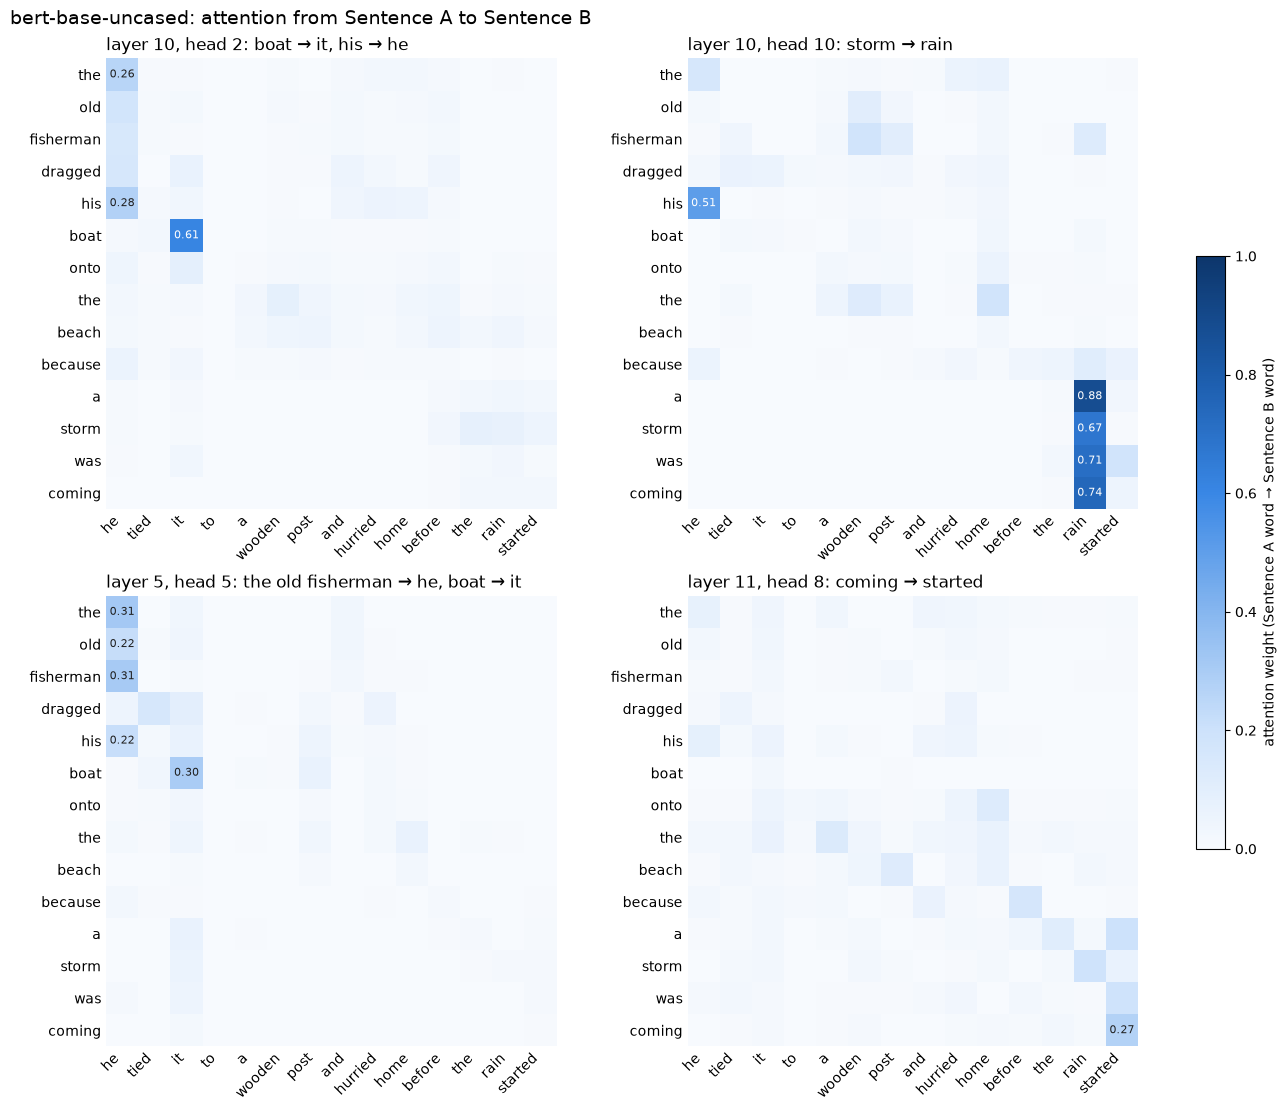

In [9]:
heads = [(10, 2, "boat → it, his → he"), (10, 10, "storm → rain"), (5, 5, "the old fisherman → he, boat → it"), (11, 8, "coming → started")]

cmap = LinearSegmentedColormap.from_list(
    "attn", ["#f7fafe", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

fig, axes = plt.subplots(2, 2, figsize=(13, 11), constrained_layout=True, facecolor="white")
for ax, (layer, head, label) in zip(axes.flat, heads):
    block = A[layer, head][a_idx][:, b_idx].numpy()
    im = ax.imshow(block, cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(len(b_idx)), [tokens[j] for j in b_idx], rotation=45, ha="right")
    ax.set_yticks(range(len(a_idx)), [tokens[i] for i in a_idx])
    ax.set_title(f"layer {layer}, head {head}: {label}", loc="left", fontsize=12)
    ax.tick_params(length=0, labelsize=10)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for r in range(block.shape[0]):
        for c in range(block.shape[1]):
            if block[r, c] >= 0.2:
                ax.text(c, r, f"{block[r, c]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if block[r, c] >= 0.5 else "#1f1f1f")
fig.colorbar(im, ax=axes, shrink=0.6, label="attention weight (Sentence A word → Sentence B word)")
fig.suptitle("bert-base-uncased: attention from Sentence A to Sentence B", x=0.02, ha="left", fontsize=14)
fig.savefig("lab2_bertviz_heads.png", dpi=150)
plt.show()

## Answer

**Question:** When looking at the attention between Sentence_1 → Sentence_2, did you get any patterns of attention that make sense to you? Can you give an example?

Yes. With Sentence A → Sentence B selected, a few heads connect words that belong together across the two sentences:

- **boat → it.** In layer 10, head 2, "boat" puts 0.61 of its attention on "it", the pronoun that refers back to the boat. The same head also links "his" → "he" (0.28). The other direction is even stronger: "it" puts 0.78 on "boat" in layer 9, head 1, and "boat" is the top Sentence A word for "it" in several heads of layers 8 and 9.
- **the old fisherman → he.** Layer 5, head 5 behaves like a pronoun head: "the", "old" and "fisherman" all attend to "he" (0.22–0.31), "his" → "he" gets 0.22, and the same head also sends "boat" → "it" (0.30). The "He" of Sentence B is the fisherman.
- **storm → rain.** Layer 10, head 10 gives 0.67. The same head also sends "a", "was" and "coming" to "rain" (0.71–0.88), so it seems to link the whole event "a storm was coming" to "the rain started". It also links "his" → "he" (0.51).
- **coming → started.** 0.27 in layer 11, head 8: the two verbs that describe the weather.

Not every link I expected shows up. "dragged" → "tied" and "beach" → "home" stay weak in every head (at most 0.15 and 0.11). On average over all 144 heads, Sentence A words give only 8% of their attention to Sentence B words; 34% stays on Sentence A words and 58% goes to `[CLS]`, `[SEP]` and the full stops. So the cross-sentence links live in a few specific heads, mostly in the later layers (9–11), rather than being spread across the model.